In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/customer_churn_dataset-testing-master.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (64374, 12)


In [3]:
# Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Remove identifier feature
if "CustomerID" in X.columns:
    X = X.drop("CustomerID", axis=1)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (64374, 10)
Target shape: (64374,)

Features:
['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction']

Target distribution:
Churn
0    33881
1    30493
Name: count, dtype: int64


In [4]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (51499, 10)
Testing features shape: (12875, 10)
Training target shape: (51499,)
Testing target shape: (12875,)


In [5]:
# Identify numerical and categorical features

numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']

Categorical features:
['Gender', 'Subscription Type', 'Contract Length']


In [6]:
# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed successfully!

Processed training shape: (51499, 15)
Processed testing shape: (12875, 15)


In [7]:
# Selected features identified in Notebook 04

selected_features = [
    "num__Age",
    "num__Tenure",
    "num__Usage Frequency",
    "num__Support Calls",
    "num__Payment Delay",
    "cat__Gender_Female",
    "cat__Gender_Male",
    "cat__Subscription Type_Premium",
    "cat__Contract Length_Annual",
    "cat__Contract Length_Quarterly"
]

# Get all processed feature names
feature_names = preprocessor.get_feature_names_out()

# Find the column positions of the selected features
selected_indices = [
    list(feature_names).index(feature)
    for feature in selected_features
]

# Select only the required features
X_train_selected = X_train_processed[:, selected_indices]
X_test_selected = X_test_processed[:, selected_indices]

print("Features before selection:", X_train_processed.shape[1])
print("Features after selection:", X_train_selected.shape[1])

print("\nSelected features:")
for feature in selected_features:
    print("-", feature)

Features before selection: 15
Features after selection: 10

Selected features:
- num__Age
- num__Tenure
- num__Usage Frequency
- num__Support Calls
- num__Payment Delay
- cat__Gender_Female
- cat__Gender_Male
- cat__Subscription Type_Premium
- cat__Contract Length_Annual
- cat__Contract Length_Quarterly


In [8]:
# Create Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_selected, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [9]:
# Create Random Forest model

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train_selected, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [10]:
# Create XGBoost model

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_selected, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [11]:
# Generate predictions from all three models

y_pred_logistic = logistic_model.predict(X_test_selected)
y_pred_rf = random_forest_model.predict(X_test_selected)
y_pred_xgb = xgb_model.predict(X_test_selected)

print("Predictions generated successfully!")

print("\nLogistic Regression predictions:", len(y_pred_logistic))
print("Random Forest predictions:", len(y_pred_rf))
print("XGBoost predictions:", len(y_pred_xgb))

Predictions generated successfully!

Logistic Regression predictions: 12875
Random Forest predictions: 12875
XGBoost predictions: 12875


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Convert target values to binary if they are Yes/No
if y_test.dtype == "object":
    y_test_binary = y_test.map({"No": 0, "Yes": 1})
else:
    y_test_binary = y_test

# Generate probability predictions for ROC-AUC
y_prob_logistic = logistic_model.predict_proba(X_test_selected)[:, 1]
y_prob_rf = random_forest_model.predict_proba(X_test_selected)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test_selected)[:, 1]

# Generate predictions in binary form if necessary
def convert_predictions(predictions):
    if predictions.dtype == "object":
        return pd.Series(predictions).map({"No": 0, "Yes": 1}).values
    return predictions

y_pred_logistic_binary = convert_predictions(y_pred_logistic)
y_pred_rf_binary = convert_predictions(y_pred_rf)
y_pred_xgb_binary = convert_predictions(y_pred_xgb)

# Calculate evaluation metrics
results = []

models = {
    "Logistic Regression": (y_pred_logistic_binary, y_prob_logistic),
    "Random Forest": (y_pred_rf_binary, y_prob_rf),
    "XGBoost": (y_pred_xgb_binary, y_prob_xgb)
}

for model_name, (predictions, probabilities) in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_binary, predictions),
        "Precision": precision_score(y_test_binary, predictions, pos_label=1),
        "Recall": recall_score(y_test_binary, predictions, pos_label=1),
        "F1-Score": f1_score(y_test_binary, predictions, pos_label=1),
        "ROC-AUC": roc_auc_score(y_test_binary, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.823068,0.809593,0.819151,0.814344,0.900310
1,Random Forest,0.963029,0.943105,0.981144,0.961749,0.995981
2,XGBoost,0.964583,0.944821,0.982620,0.963350,0.996156


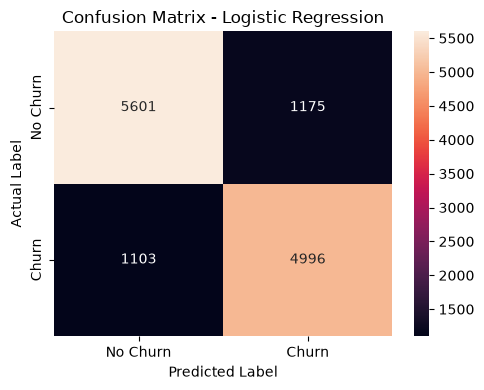

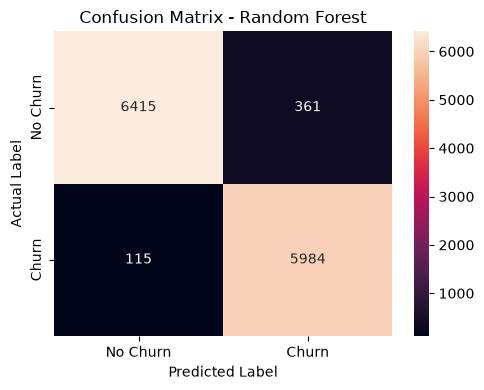

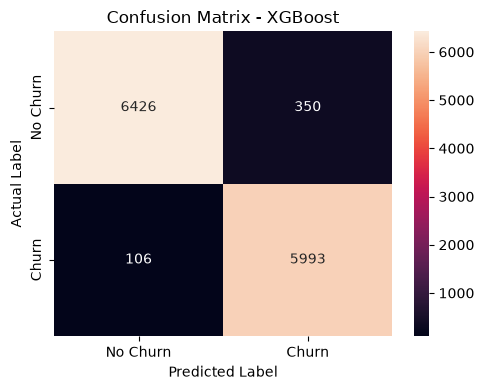

In [14]:
from sklearn.metrics import confusion_matrix

# Create confusion matrices
cm_logistic = confusion_matrix(y_test_binary, y_pred_logistic_binary)
cm_rf = confusion_matrix(y_test_binary, y_pred_rf_binary)
cm_xgb = confusion_matrix(y_test_binary, y_pred_xgb_binary)

# Store matrices and model names
confusion_matrices = {
    "Logistic Regression": cm_logistic,
    "Random Forest": cm_rf,
    "XGBoost": cm_xgb
}

# Display confusion matrices
for model_name, cm in confusion_matrices.items():
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

In [15]:
from sklearn.metrics import classification_report

# Generate classification reports

print("=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)

print(classification_report(
    y_test_binary,
    y_pred_logistic_binary,
    target_names=["No Churn", "Churn"]
))


print("=" * 60)
print("RANDOM FOREST")
print("=" * 60)

print(classification_report(
    y_test_binary,
    y_pred_rf_binary,
    target_names=["No Churn", "Churn"]
))


print("=" * 60)
print("XGBOOST")
print("=" * 60)

print(classification_report(
    y_test_binary,
    y_pred_xgb_binary,
    target_names=["No Churn", "Churn"]
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    No Churn       0.84      0.83      0.83      6776
       Churn       0.81      0.82      0.81      6099

    accuracy                           0.82     12875
   macro avg       0.82      0.82      0.82     12875
weighted avg       0.82      0.82      0.82     12875

RANDOM FOREST
              precision    recall  f1-score   support

    No Churn       0.98      0.95      0.96      6776
       Churn       0.94      0.98      0.96      6099

    accuracy                           0.96     12875
   macro avg       0.96      0.96      0.96     12875
weighted avg       0.96      0.96      0.96     12875

XGBOOST
              precision    recall  f1-score   support

    No Churn       0.98      0.95      0.97      6776
       Churn       0.94      0.98      0.96      6099

    accuracy                           0.96     12875
   macro avg       0.96      0.97      0.96     12875
weighted avg       0.97      0.9

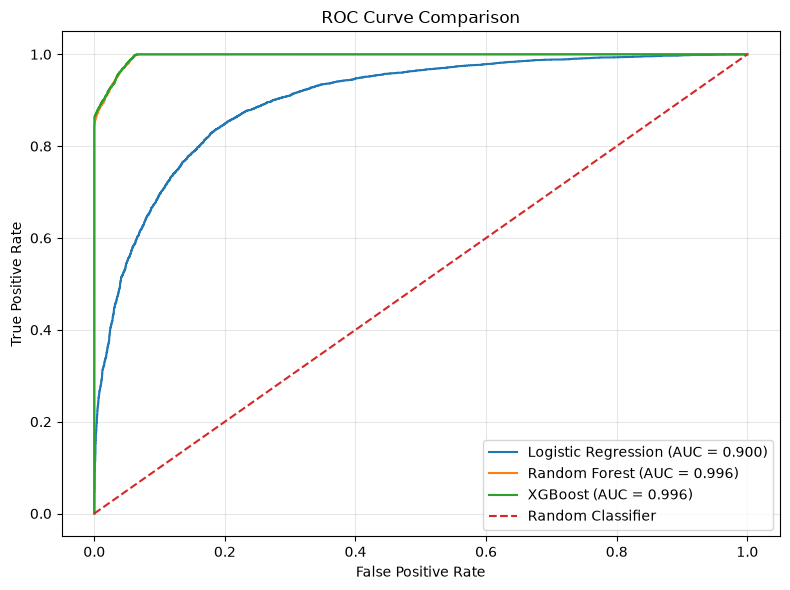

In [16]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve values
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test_binary, y_prob_logistic
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test_binary, y_prob_rf
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test_binary, y_prob_xgb
)

# Calculate AUC values
auc_logistic = auc(fpr_logistic, tpr_logistic)
auc_rf = auc(fpr_rf, tpr_rf)
auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {auc_logistic:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {auc_xgb:.3f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Display model comparison table

print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8231,0.8096,0.8192,0.8143,0.9003
1,Random Forest,0.9630,0.9431,0.9811,0.9617,0.9960
2,XGBoost,0.9646,0.9448,0.9826,0.9633,0.9962


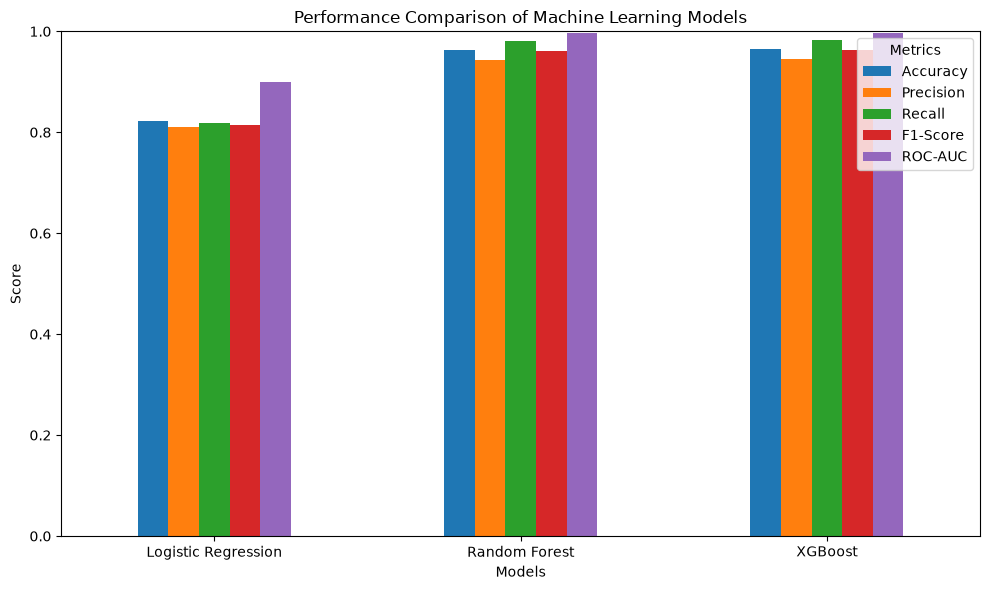

In [18]:
# Prepare data for visualization

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

comparison_plot = results_df.set_index("Model")[metrics]

# Plot model comparison
comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Models")
plt.ylabel("Score")
plt.title("Performance Comparison of Machine Learning Models")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [20]:
# Get churn probabilities from each base model

prob_logistic = logistic_model.predict_proba(X_test_selected)[:, 1]
prob_rf = random_forest_model.predict_proba(X_test_selected)[:, 1]
prob_xgb = xgb_model.predict_proba(X_test_selected)[:, 1]

print("Probability predictions generated successfully!")

print("\nLogistic Regression probabilities:", len(prob_logistic))
print("Random Forest probabilities:", len(prob_rf))
print("XGBoost probabilities:", len(prob_xgb))

Probability predictions generated successfully!

Logistic Regression probabilities: 12875
Random Forest probabilities: 12875
XGBoost probabilities: 12875


In [21]:
# Define equal weights for the three base models

weight_logistic = 1 / 3
weight_rf = 1 / 3
weight_xgb = 1 / 3

# Calculate hybrid ensemble probability

ensemble_probability = (
    weight_logistic * prob_logistic +
    weight_rf * prob_rf +
    weight_xgb * prob_xgb
)

print("Hybrid ensemble probability calculated successfully!")
print("Number of ensemble predictions:", len(ensemble_probability))

Hybrid ensemble probability calculated successfully!
Number of ensemble predictions: 12875


In [22]:
# Convert ensemble probabilities into final predictions

ensemble_prediction = (ensemble_probability >= 0.5).astype(int)

print("Hybrid ensemble predictions generated successfully!")

print("\nNumber of predictions:", len(ensemble_prediction))

print("\nPrediction distribution:")
print(pd.Series(ensemble_prediction).value_counts())

Hybrid ensemble predictions generated successfully!

Number of predictions: 12875

Prediction distribution:
0    6542
1    6333
Name: count, dtype: int64


In [23]:
# Evaluate hybrid ensemble

ensemble_accuracy = accuracy_score(
    y_test_binary,
    ensemble_prediction
)

ensemble_precision = precision_score(
    y_test_binary,
    ensemble_prediction,
    pos_label=1
)

ensemble_recall = recall_score(
    y_test_binary,
    ensemble_prediction,
    pos_label=1
)

ensemble_f1 = f1_score(
    y_test_binary,
    ensemble_prediction,
    pos_label=1
)

ensemble_roc_auc = roc_auc_score(
    y_test_binary,
    ensemble_probability
)

print("HYBRID ENSEMBLE PERFORMANCE")
print("=" * 50)

print(f"Accuracy  : {ensemble_accuracy:.4f}")
print(f"Precision : {ensemble_precision:.4f}")
print(f"Recall    : {ensemble_recall:.4f}")
print(f"F1-Score  : {ensemble_f1:.4f}")
print(f"ROC-AUC   : {ensemble_roc_auc:.4f}")

HYBRID ENSEMBLE PERFORMANCE
Accuracy  : 0.9649
Precision : 0.9458
Recall    : 0.9821
F1-Score  : 0.9636
ROC-AUC   : 0.9937


In [24]:
# Create hybrid ensemble results

ensemble_results = pd.DataFrame([{
    "Model": "Hybrid Ensemble",
    "Accuracy": ensemble_accuracy,
    "Precision": ensemble_precision,
    "Recall": ensemble_recall,
    "F1-Score": ensemble_f1,
    "ROC-AUC": ensemble_roc_auc
}])

# Combine base model results with ensemble results

final_results_df = pd.concat(
    [results_df, ensemble_results],
    ignore_index=True
)

print("FINAL MODEL COMPARISON")
print("=" * 70)

display(
    final_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8231,0.8096,0.8192,0.8143,0.9003
1,Random Forest,0.9630,0.9431,0.9811,0.9617,0.9960
2,XGBoost,0.9646,0.9448,0.9826,0.9633,0.9962
3,Hybrid Ensemble,0.9649,0.9458,0.9821,0.9636,0.9937


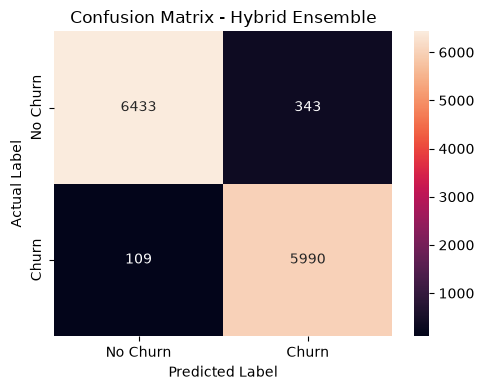

In [25]:
# Calculate confusion matrix for hybrid ensemble

cm_ensemble = confusion_matrix(
    y_test_binary,
    ensemble_prediction
)

# Plot confusion matrix

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_ensemble,
    annot=True,
    fmt="d",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Hybrid Ensemble")
plt.tight_layout()
plt.show()

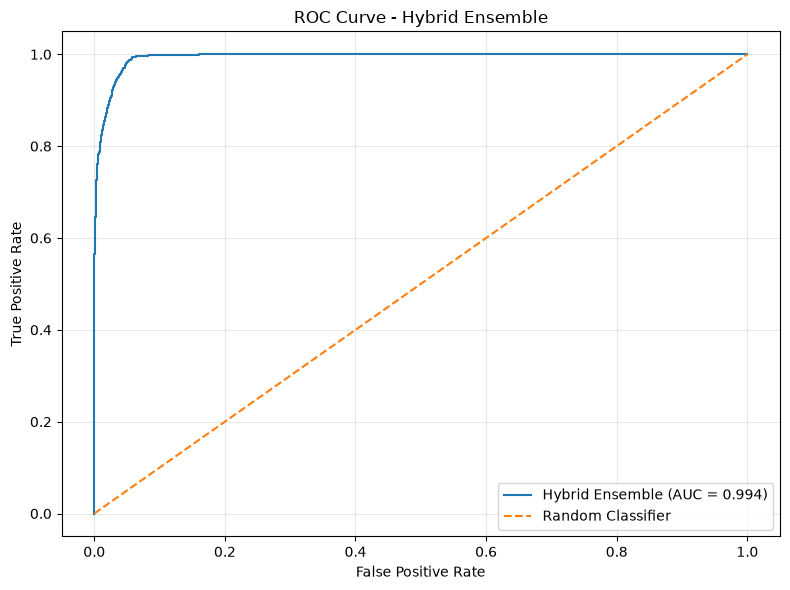

Hybrid Ensemble ROC-AUC: 0.9937


In [26]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve for hybrid ensemble

fpr_ensemble, tpr_ensemble, _ = roc_curve(
    y_test_binary,
    ensemble_probability
)

ensemble_auc = auc(
    fpr_ensemble,
    tpr_ensemble
)

# Plot ROC curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_ensemble,
    tpr_ensemble,
    label=f"Hybrid Ensemble (AUC = {ensemble_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Hybrid Ensemble")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Hybrid Ensemble ROC-AUC: {ensemble_auc:.4f}")

In [27]:
import shap

# Create SHAP Tree Explainer for XGBoost
explainer = shap.TreeExplainer(xgb_model)

print("SHAP Tree Explainer created successfully!")

SHAP Tree Explainer created successfully!


In [28]:
# Select a sample of test data for SHAP analysis

sample_size = min(1000, X_test_selected.shape[0])

X_shap = X_test_selected[:sample_size]

print("SHAP sample shape:", X_shap.shape)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")

SHAP sample shape: (1000, 10)
SHAP values calculated successfully!


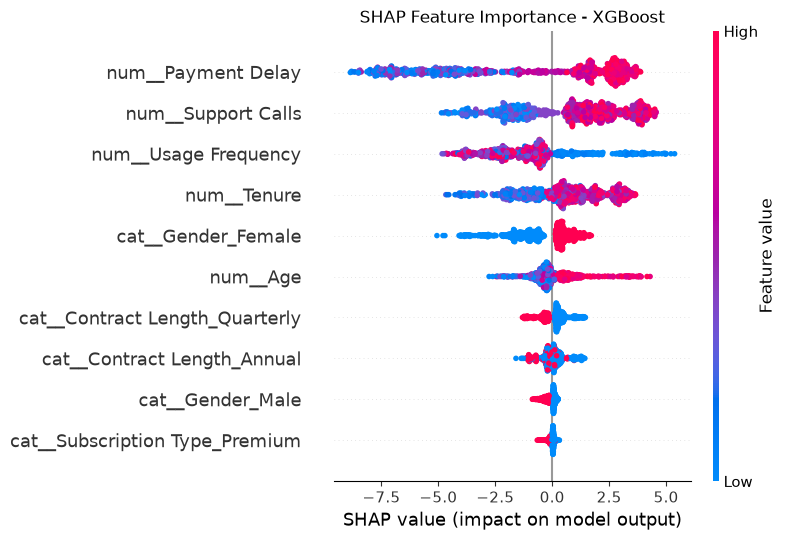

In [29]:
# SHAP summary plot

plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=selected_features,
    show=False
)

plt.title("SHAP Feature Importance - XGBoost")
plt.tight_layout()
plt.show()

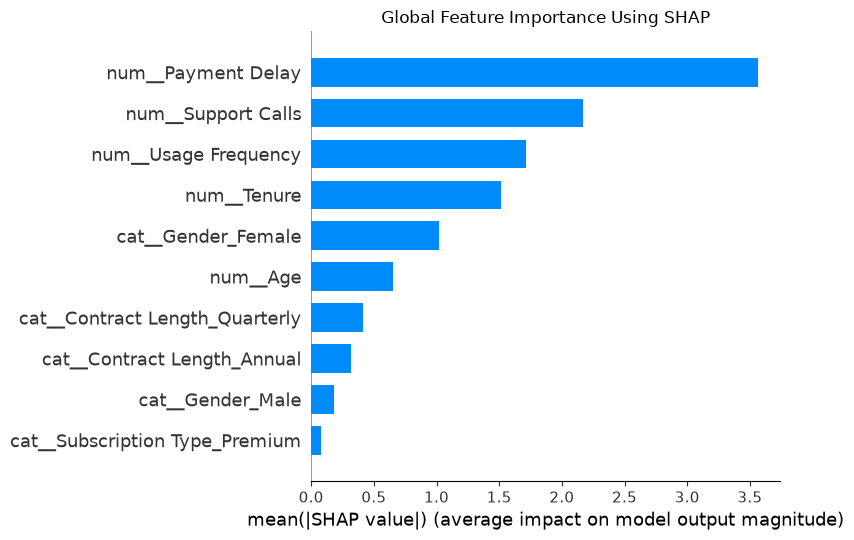

In [30]:
# SHAP global feature importance bar plot

plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=selected_features,
    plot_type="bar",
    show=False
)

plt.title("Global Feature Importance Using SHAP")
plt.tight_layout()
plt.show()

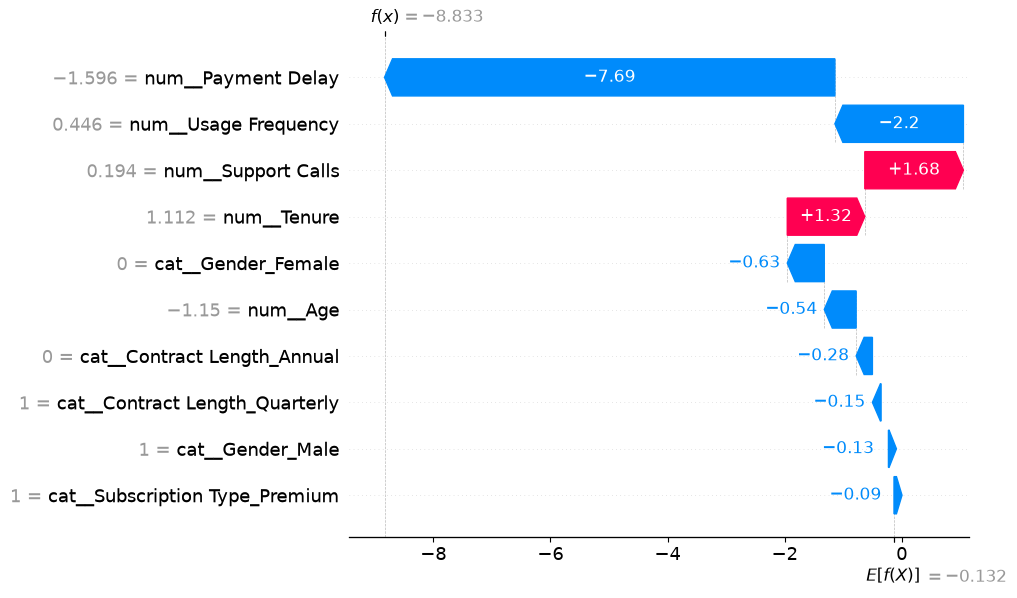

In [31]:
# Explain one customer using SHAP

customer_index = 0

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[customer_index],
        base_values=explainer.expected_value,
        data=X_shap[customer_index],
        feature_names=selected_features
    ),
    max_display=10
)

In [32]:
# Compare actual and predicted result for the selected customer

actual_value = y_test_binary.iloc[customer_index]
predicted_value = ensemble_prediction[customer_index]
probability = ensemble_probability[customer_index]

print("INDIVIDUAL CUSTOMER PREDICTION")
print("=" * 50)

print("Actual Status      :", "Churn" if actual_value == 1 else "No Churn")
print("Predicted Status   :", "Churn" if predicted_value == 1 else "No Churn")
print(f"Ensemble Probability: {probability:.4f}")

INDIVIDUAL CUSTOMER PREDICTION
Actual Status      : No Churn
Predicted Status   : No Churn
Ensemble Probability: 0.0066


In [33]:
print("SHAP EXPLAINABILITY SUMMARY")
print("=" * 60)

print("Model explained        : XGBoost")
print("Number of features     :", len(selected_features))
print("Customers analyzed     :", sample_size)

print("\nSelected features:")
for feature in selected_features:
    print("-", feature)

print("\nSHAP explainability analysis completed successfully!")

SHAP EXPLAINABILITY SUMMARY
Model explained        : XGBoost
Number of features     : 10
Customers analyzed     : 1000

Selected features:
- num__Age
- num__Tenure
- num__Usage Frequency
- num__Support Calls
- num__Payment Delay
- cat__Gender_Female
- cat__Gender_Male
- cat__Subscription Type_Premium
- cat__Contract Length_Annual
- cat__Contract Length_Quarterly

SHAP explainability analysis completed successfully!
